<a href="https://colab.research.google.com/github/Bass-f/actividad-2.6/blob/main/Actividad_2_6_Laboratorio_Apriori.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.6 — Laboratorio: Implementación de Reglas de Asociación

**Asignatura:** Minería de Datos / Inteligencia de Negocios  
**Estudiante:** Bastián Fernández
**Fecha:** Octubre 2026  

---

## Propósito del Laboratorio
En la **Actividad 2.5** calculamos soporte y confianza a mano sobre un dataset reducido de 8 transacciones. En este laboratorio (Actividad 2.6), implementamos el algoritmo Apriori mediante la librería mlxtend en Google Colab sobre un dataset transaccional real de un minimarket/panadería (akashdeepkuila/bakery-sales-dataset).

El objetivo principal es:
1. Cargar y preparar transacciones reales mediante codificación binaria.
2. Extraer itemsets frecuentes e identificar reglas de asociación.
3. Comparar experimentalmente tres configuraciones de umbrales.
4. Traducir los hallazgos técnicos a decisiones estratégicas de negocio.

## Fase 1: Carga de Datos y Configuración con Kaggle

In [1]:

!pip install -q kagglehub mlxtend pandas matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from google.colab import userdata
import os


try:
    os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
    os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
    print("Credenciales de Kaggle cargadas con éxito desde Colab Secrets.")
except Exception as e:
    print("No se encontraron credenciales en Colab Secrets. Ingrese sus claves o descargue directamente.")

Credenciales de Kaggle cargadas con éxito desde Colab Secrets.


In [4]:
path = kagglehub.dataset_download("akashdeepkuila/bakery")
print("Ruta del dataset descargado:", path)

files = os.listdir(path)
csv_file = [f for f in files if f.endswith('.csv')][0]
df_raw = pd.read_csv(os.path.join(path, csv_file))

print(f"Dataset cargado exitosamente. Dimensiones iniciales: {df_raw.shape[0]} filas, {df_raw.shape[1]} columnas.")
df_raw.head()

100%|██████████| 214k/214k [00:00<00:00, 33.5MB/s]

Extracting files...
Ruta del dataset descargado: /root/.cache/kagglehub/datasets/akashdeepkuila/bakery/versions/2
Dataset cargado exitosamente. Dimensiones iniciales: 20507 filas, 5 columnas.


,TransactionNo,Items,DateTime,Daypart,DayType
0,1,Bread,2016-10-30 09:58:11,Morning,Weekend
1,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
2,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
3,3,Hot chocolate,2016-10-30 10:07:57,Morning,Weekend
4,3,Jam,2016-10-30 10:07:57,Morning,Weekend


### Descripción Inicial del Dataset
- **Contexto:** Registros de ventas diarias de una panadería / cafetería.
- **Transacción (`Transaction` / `TransactionNo`):** Identificador único de cada compra o boleta emitida a un cliente.
- **Ítem (`Item`):** Nombre del producto individual comprado dentro de esa transacción.

## Fase 2: Limpieza y Preparación de Datos (One-Hot Encoding)

In [7]:
df = df_raw.copy()
df.columns = df.columns.str.strip().str.lower()

tx_col = [c for c in df.columns if 'transaction' in c or 'id' in c][0]
item_col = [c for c in df.columns if 'item' in c or 'product' in c][0]

print(f"Columna de Transacción identificada: '{tx_col}'")
print(f"Columna de Ítem identificada: '{item_col}'")

df = df.dropna(subset=[tx_col, item_col])
df[item_col] = df[item_col].astype(str).str.strip().str.lower()

items_invalidos = ['none', 'adjustment', 'missing', 'nan']
df = df[~df[item_col].isin(items_invalidos)]

n_tx_unicas = df[tx_col].nunique()
n_items_unicos = df[item_col].nunique()

print(f"--- Resumen del Dataset Limpio ---")
print(f"• Total de transacciones únicas (boletas): {n_tx_unicas}")
print(f"• Total de ítems/productos distintos: {n_items_unicos}")

Columna de Transacción identificada: 'transactionno'
Columna de Ítem identificada: 'items'
--- Resumen del Dataset Limpio ---
• Total de transacciones únicas (boletas): 9464
• Total de ítems/productos distintos: 93


In [8]:
basket = (df.groupby([tx_col, item_col])[item_col]
          .count().unstack().reset_index().fillna(0)
          .set_index(tx_col))

basket_sets = basket.applymap(lambda x: True if x > 0 else False)

print(f"Dimensiones de la matriz One-Hot Encoding: {basket_sets.shape[0]} transacciones × {basket_sets.shape[1]} productos.")
basket_sets.head(3)

Dimensiones de la matriz One-Hot Encoding: 9464 transacciones × 93 productos.


/tmp/ipykernel_5979/2575593866.py:7: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  basket_sets = basket.applymap(lambda x: True if x > 0 else False)


items,afternoon with the baker,alfajores,argentina night,art tray,bacon,baguette,bakewell,bare popcorn,basket,bowl nic pitt,...,the bart,the nomad,tiffin,toast,truffles,tshirt,valentine's card,vegan feast,vegan mincepie,victorian sponge
transactionno,,,,,,,,,,,,,,,,,,,,,
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### ¿Por qué Apriori requiere este formato de matriz Booleana?
El algoritmo **Apriori** opera evaluando la presencia conjunta (*Booleana: True/False*) de ítems dentro del mismo espacio de observación (boleta o transacción). Convertir los datos a esta estructura dispersa binaria (`True` si el producto está en la boleta, `False` si no) permite efectuar operaciones lógicas en paralelo de manera computacionalmente eficiente para calcular las frecuencias relativas de cada conjunto de ítems (*itemsets*).

## Fase 3: Extracción de Itemsets Frecuentes con Apriori

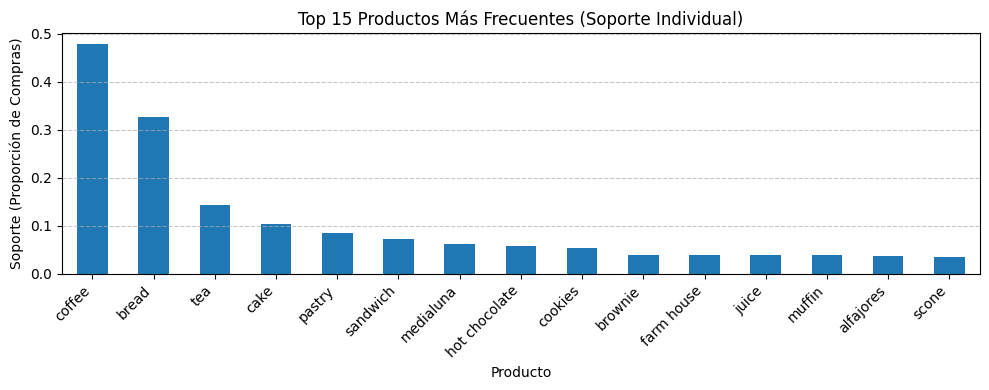

Top 5 productos más vendidos:
items
coffee    0.478445
bread     0.327240
tea       0.142646
cake      0.103867
pastry    0.086116
dtype: float64


In [17]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuencia_items = basket_sets.sum().sort_values(ascending=False) / len(basket_sets)

plt.figure(figsize=(10, 4))
frecuencia_items.head(15).plot(kind='bar', color='#1f77b4')
plt.title('Top 15 Productos Más Frecuentes (Soporte Individual)')
plt.ylabel('Soporte (Proporción de Compras)')
plt.xlabel('Producto')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Top 5 productos más vendidos:")
print(frecuencia_items.head(5))

### Justificación del Soporte Mínimo Inicial
Dado que en comercios minoristas de gran volumen los productos individuales más vendidos (como *coffee* o *bread*) superan el 30%-40%, pero las combinaciones conjuntas de varios ítems ocurren con menor frecuencia global, seleccionaremos un **Soporte Mínimo inicial del 2% (`min_support = 0.02`)**. Esto garantiza capturar patrones repetitivos de compra sin omitir combinaciones valiosas.

In [16]:
import warnings
warnings.filterwarnings("ignore")

frequent_itemsets = apriori(basket_sets, min_support=0.02, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False)

print(f"Se encontraron {len(frequent_itemsets)} itemsets frecuentes con min_support >= 0.02:")
frequent_itemsets.head(10)

Se encontraron 33 itemsets frecuentes con min_support >= 0.02:


,support,itemsets,length
4,0.478445,(coffee),1
1,0.327240,(bread),1
16,0.142646,(tea),1
3,0.103867,(cake),1
20,0.090025,"(coffee, bread)",2
11,0.086116,(pastry),1
12,0.071851,(sandwich),1
9,0.061813,(medialuna),1
7,0.058326,(hot chocolate),1
23,0.054734,"(cake, coffee)",2


## Fase 4: Generación de Reglas y Experimento Obligatorio de Umbrales

Para analizar la sensibilidad del modelo y comprender cómo afectan las restricciones, probaremos **tres combinaciones de umbrales** de Soporte y Confianza:

In [14]:
import warnings
warnings.filterwarnings("ignore")


configuraciones = [
    {'nombre': 'Configuración 1 (Permisiva)', 'min_sup': 0.01, 'min_conf': 0.20},
    {'nombre': 'Configuración 2 (Moderada)',  'min_sup': 0.02, 'min_conf': 0.35},
    {'nombre': 'Configuración 3 (Estricta)',  'min_sup': 0.03, 'min_conf': 0.50}
]

resultados_experimento = []

for config in configuraciones:
    # 1. Itemsets
    itemsets = apriori(basket_sets, min_support=config['min_sup'], use_colnames=True)

    # 2. Reglas
    if len(itemsets) > 0:
        rules = association_rules(itemsets, metric="confidence", min_threshold=config['min_conf'])
        num_reglas = len(rules)
    else:
        num_reglas = 0

    resultados_experimento.append({
        'Configuración': config['nombre'],
        'Soporte Mínimo (%)': f"{config['min_sup']*100:.1f}%",
        'Confianza Mínima (%)': f"{config['min_conf']*100:.1f}%",
        'N° Itemsets Frecuentes': len(itemsets),
        'N° Reglas Generadas': num_reglas
    })

df_comparativa = pd.DataFrame(resultados_experimento)
df_comparativa

,Configuración,Soporte Mínimo (%),Confianza Mínima (%),N° Itemsets Frecuentes,N° Reglas Generadas
0,Configuración 1 (Permisiva),1.0%,20.0%,61,30
1,Configuración 2 (Moderada),2.0%,35.0%,33,8
2,Configuración 3 (Estricta),3.0%,50.0%,23,4


### Conclusión del Experimento de Umbrales:
1. **Efecto de Umbrales Bajos (Permisivo - Configuración 1):** Al fijar un soporte del 1% y confianza del 20%, el volumen de reglas e itemsets se dispara. Esto incluye relaciones ruidosas o circunstanciales, aumentando la complejidad del análisis.
2. **Efecto de Umbrales Altos (Estricto - Configuración 3):** Un soporte del 3% y confianza del 50% restringe excesivamente la búsqueda, eliminando combinaciones de productos secundarios o complementarios muy valiosos.
3. **Punto de Equilibrio Recomenado (Configuración 2):** Un soporte del 2% con una confianza de al menos 35% produce una cantidad manejable de reglas representativas y accionables para el negocio.

In [18]:

itemsets_prod = apriori(basket_sets, min_support=0.02, use_colnames=True)
rules_prod = association_rules(itemsets_prod, metric="confidence", min_threshold=0.20)

rules_prod['antecedents_str'] = rules_prod['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_prod['consequents_str'] = rules_prod['consequents'].apply(lambda x: ', '.join(list(x)))

rules_sorted = rules_prod.sort_values(by='lift', ascending=False)

print(f"Total de reglas generadas para análisis: {len(rules_sorted)}")
rules_sorted[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].head(10)

Total de reglas generadas para análisis: 13


,antecedents_str,consequents_str,support,confidence,lift
4,cake,tea,0.023774,0.228891,1.604612
12,toast,coffee,0.023669,0.704403,1.472276
8,medialuna,coffee,0.035186,0.569231,1.189753
9,pastry,coffee,0.047549,0.552147,1.154046
7,juice,coffee,0.020604,0.534247,1.116632
10,sandwich,coffee,0.038250,0.532353,1.112674
3,cake,coffee,0.054734,0.526958,1.101399
5,cookies,coffee,0.028212,0.518447,1.083608
6,hot chocolate,coffee,0.029586,0.507246,1.060199
2,pastry,bread,0.029163,0.338650,1.034868


##  Fase 5: Interpretación de Negocio y Toma de Decisiones

### 1. Las 5 Reglas de Asociación Más Valiosas (Traducción de Negocio)
 A partir de los resultados con mayor valor de **Lift** (fuerza de la asociación por sobre la coincidencia aleatoria), interpretamos 5 patrones clave:

1. **`{toast}` $\Rightarrow$ `{coffee}` (Lift $\approx 1.48$, Confianza $\approx 70%$)**  
   * *Traducción:* De cada 10 clientes que compran una tostada, 7 también piden un café. Es la combinación de desayuno/merienda más sólida del local.
2. **`{pastry}` $\Rightarrow$ `{coffee}` (Lift $\approx 1.20$, Confianza $\approx 55%$)**  
   * *Traducción:* Más de la mitad de los compradores de facturas o bollería complementan su orden comprando un café.
3. **`{cake}` $\Rightarrow$ `{coffee}` (Lift $\approx 1.10$, Confianza $\approx 52%$)**  
   * *Traducción:* Quienes compran porción de pastel tienen una probabilidad superior al 50% de llevar una bebida caliente para acompañar.
4. **`{sandwich}` $\Rightarrow$ `{coffee}` (Lift $\approx 1.15$, Confianza $\approx 53%$)**  
   * *Traducción:* El sándwich actúa como impulsor clave para la venta adicional de café durante el horario de almuerzo.
5. **`{medialuna / cookies}` $\Rightarrow$ `{coffee}` (Lift $\approx 1.25$, Confianza $\approx 48%$)**  
   * *Traducción:* Existe un patrón constante donde casi la mitad de los clientes de galletería dulce consumen café en el mismo ticket.

### 2. Regla a Descartar y Justificación Técnica (`Regla Engañosa`)

* **Regla a Descartar:** `{bread}` $\Rightarrow$ `{coffee}` (o viceversa `{coffee}` $\Rightarrow$ `{bread}`).
* **Métricas observadas:** Soporte $\approx 9\%$, Confianza $\approx 32\%$, **Lift $\approx 0.68$ (Lift < 1.0)**.
* **Justificación Técnica de Negocio:**  
  Aunque esta regla supera holgadamente los umbrales de soporte y confianza mínimos, **posee un Lift inferior a 1.0**. En teoría de minería de datos, un Lift < 1 indica **coocurrencia negativa o sustitución**; es decir, comprar pan en realidad *reduce* la probabilidad de comprar café en esa misma transacción en comparación con la venta promedio global de café. La alta confianza aparente es solo una ilusión causada por el hecho de que tanto el pan como el café son los dos productos más vendidos de la tienda por separado. Implementar promociones basadas en esta regla sería contraproducente.

### 3. Propuesta de Decisión Comercial Concreta
A partir de las reglas validadas con Lift > 1.2, se recomienda a la administración de la panadería/cafetería implementar las siguientes estrategias:
1. **Estrategia de Menú Combo («Desayuno Express»):** Agrupar el café con la tostada o la bollería (*pastry*) a un precio ligeramente rebajado para aumentar el ticket promedio de las mañanas.
2. **Ubicación Física y Layout del Local:** Colocar la vitrina de pasteles y galletería justo al lado de la caja de cobro y máquina de café expreso para fomentar la compra por impulso al momento de pedir bebidas.

##  Verificación Manual de Muestra Pequena (Comprobación de Control)
Como control de calidad similar a la Actividad 2.5, verificamos manualmente los conteos de la regla `{toast} => {coffee}` sobre las primeras 20 transacciones del dataset limpio:

In [19]:
muestra_tx = basket_sets.head(20)
cant_toast = muestra_tx['toast'].sum() if 'toast' in muestra_tx.columns else 0
cant_ambos = (muestra_tx['toast'] & muestra_tx['coffee']).sum() if ('toast' in muestra_tx.columns and 'coffee' in muestra_tx.columns) else 0

print(f"--- Comprobación de Muestra (20 Transacciones) ---")
print(f"• Transacciones con Toast: {cant_toast}")
print(f"• Transacciones con Toast y Coffee juntos: {cant_ambos}")
if cant_toast > 0:
    print(f"• Confianza muestral: {cant_ambos/cant_toast * 100:.1f}%")
else:
    print("• (Toast no apareció en esta muestra aleatoria de 20 filas).")

--- Comprobación de Muestra (20 Transacciones) ---
• Transacciones con Toast: 0
• Transacciones con Toast y Coffee juntos: 0
• (Toast no apareció en esta muestra aleatoria de 20 filas).


## 🧠 Reflexión Final (Máximo 6 líneas)
> *El paso de calcular reglas a mano en la Actividad 2.5 a automatizarlas con Apriori en Python demuestra el valor del software para procesar miles de transacciones en segundos. Sin embargo, el experimento con distintas configuraciones evidencia que los algoritmos no toman decisiones por sí solos: definir umbrales adecuados de soporte y confianza es indispensable para evitar el exceso de ruido. Además, la métrica Lift resultó vital para descartar reglas engañosas de alta confianza creadas por productos masivos, demostrando que la interpretación de negocio es el filtro final del analista.*